In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

RANDOM_STATE = 42

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")

df.drop_duplicates()

print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [4]:
display(df.describe(include='object').T)

,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,B96 B98,4
Embarked,889,3,S,644


In [5]:
miss = pd.DataFrame({"пропусков": df.isna().sum(), "доля, %": (df.isna().mean() * 100).round(1)})
display(miss[miss["пропусков"] > 0])
print("Полных дубликатов строк:", df.duplicated().sum())
print("Дубликатов по Name:", df["Name"].duplicated().sum())
print("Уникальных значений в PassengerId / Name / Ticket / Cabin:",
      df["PassengerId"].nunique(), df["Name"].nunique(), df["Ticket"].nunique(), df["Cabin"].nunique())

,пропусков,"доля, %"
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


Полных дубликатов строк: 0
Дубликатов по Name: 0
Уникальных значений в PassengerId / Name / Ticket / Cabin: 891 891 681 147


**Вывод.** Полных дубликатов нет. Пропуски: `Age` (≈20%), `Cabin` (≈77%), `Embarked` (2 строки). Классы несбалансированы умеренно: 61.6% погибших и 38.4% выживших. Это значит, что наивный «всегда предсказывать 0» даст Accuracy ≈ 0.62, поэтому Accuracy сама по себе плохой ориентир, и в качестве основной метрики выбран F1 по положительному классу.

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    61.6
1    38.4
Name: proportion, dtype: float64


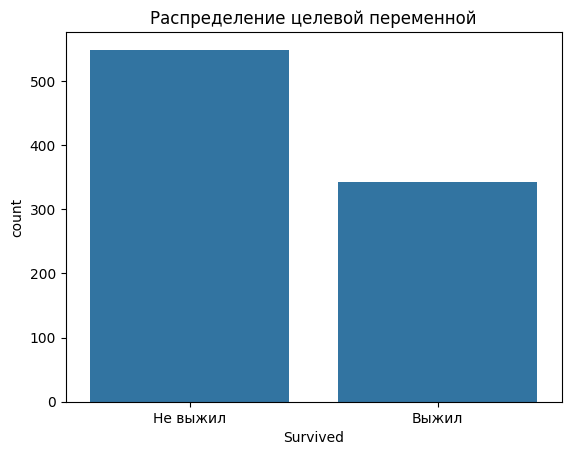

In [7]:
counts = df["Survived"].value_counts()
print(counts)
print((df["Survived"].value_counts(normalize=True) * 100).round(1))
ax = sns.countplot(data=df, x="Survived")
ax.set_xticks(ticks=[0, 1], labels=["Не выжил", "Выжил"])
ax.set_title("Распределение целевой переменной")
plt.show()

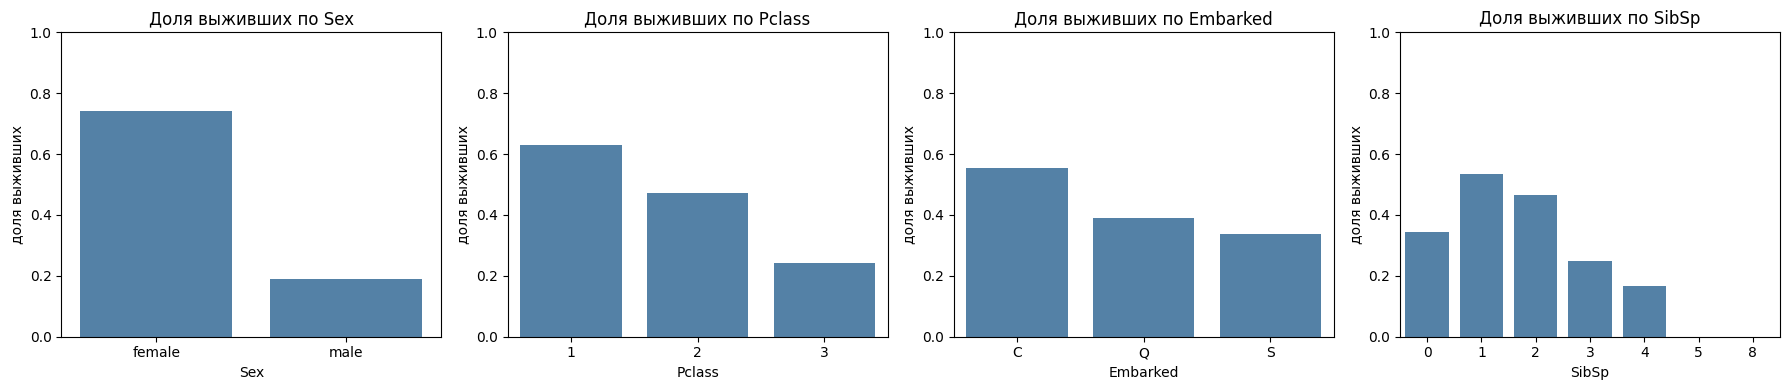

Pclass,1,2,3
Sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked", "SibSp"]):
    rate = df.groupby(col)["Survived"].mean()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="steelblue")
    ax.set_title(f"Доля выживших по {col}")
    ax.set_ylim(0, 1)
    ax.set_ylabel("доля выживших")
plt.tight_layout()
plt.show()

display(df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean").round(2))

**Вывод**: среди выживших имеется некоторый перевес в сторону женщин, что согласуется с правилом "уступать место в спасательных шлюпках женщинам и детям". Также видно, что на выживаемость влиял и класс пассажирского билета. Это значит, что на предсказание влияет сочетания признаков, что хорошо для ядерных методов и деревьев решений.

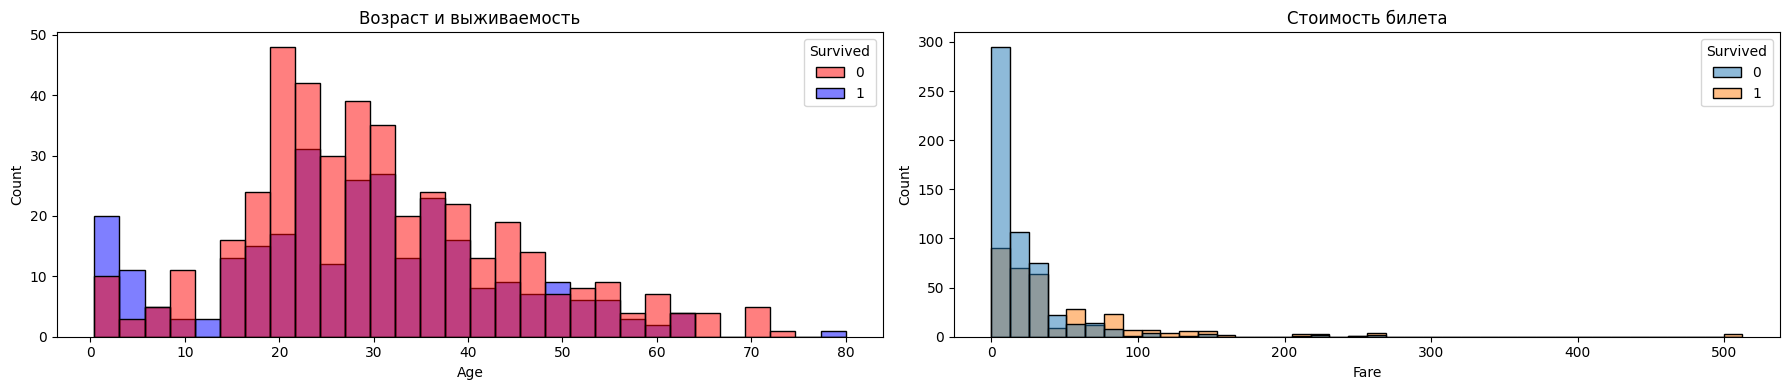

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=False, ax=axes[0], multiple="layer", palette={0: "red", 1: "blue"})
axes[0].set_title("Возраст и выживаемость")
sns.histplot(data=df, x="Fare", hue="Survived", bins=40, ax=axes[1], multiple="layer")
axes[1].set_title("Стоимость билета")
plt.tight_layout()
plt.show()

Как видно обе гистограммы `Fare` и `Age` имеют выраженный правый хвост, что отражает, что выживаемость среди людей, купивших более дорогие билеты и не являющиеся членами экипажа (их билет бесплатный), была выше. Правый хвост как минимум по этим признакам означает, что данные необходимо стандартизировать, так как модели SVM и KNN чувствительны к масштабу данных

In [ ]:
from sklearn.model_selection import train_test_split

X = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", ]].copy()
y = df["Survived"]

title = df["Name"].str.extract(r",\s*([^.]+)\.", expand=False)
print(title.value_counts().to_dict())
X["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
print(X["Title"].value_counts().to_dict())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
print("Доля выживших: train %.3f, test %.3f" % (y_train.mean(), y_test.mean()))

{'Mr': 517, 'Miss': 182, 'Mrs': 125, 'Master': 40, 'Dr': 7, 'Rev': 6, 'Mlle': 2, 'Major': 2, 'Col': 2, 'the Countess': 1, 'Capt': 1, 'Ms': 1, 'Sir': 1, 'Lady': 1, 'Mme': 1, 'Don': 1, 'Jonkheer': 1}
{'Mr': 517, 'Miss': 182, 'Mrs': 125, 'Master': 40, 'Rare': 27}
(712, 9) (179, 9)
Доля выживших: train 0.383, test 0.385


In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer


num_cols = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
cat_cols = ["Sex", "Embarked", "Title", "Cabin"]

prep = make_column_transformer(
    (SimpleImputer(strategy="median"), num_cols),
    (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder()), cat_cols))

prep_scaled = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder()), cat_cols))

Пропуски в `Age` заполняем **медианой** (признак скошен, медиана устойчива к выбросам), в `Embarked` - **модой**. Категориальные признаки кодируем **One-Hot** (категории не упорядочены). Разбиение 80/20 со **стратификацией**.

**Масштабирование** нужно SVM и KNN (они считают расстояния (для ширины полосы и расстояния до соседей соответственно), и `Fare` с диапазоном до 500 забьёт остальные признаки), а деревьям, Random Forest и Gradient Boosting - нет (они сравнивают каждый признак с порогом по отдельности). Все преобразования лежат внутри `make_pipeline`, поэтому обучение происходит только на train.

In [27]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

results = {}

def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "F1 train": f1_score(y_train, model.predict(X_train), zero_division=0),
    }
    ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues", colorbar=False)
    plt.title(name)
    plt.show()
    return pd.Series(results[name]).round(3)

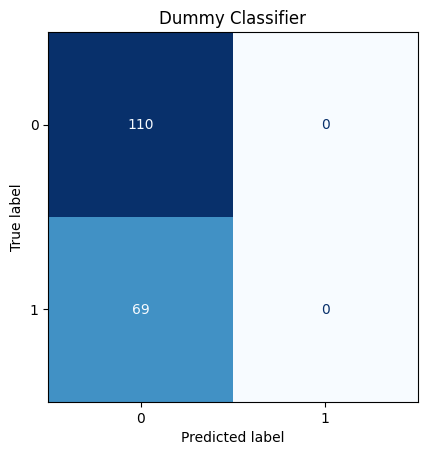

Accuracy     0.615
Precision    0.000
Recall       0.000
F1           0.000
F1 train     0.000
dtype: float64

In [ ]:
from sklearn.dummy import DummyClassifier

dummy_model = make_pipeline(prep, DummyClassifier(strategy="most_frequent"))
evaluate("Dummy Classifier", dummy_model)

Смотрим на метрики и делаем выводы, что модель считает, что **пассажир погиб**. И считает она так всегда. Такой вывод можно сделать из того, что $$precision = \frac{TP}{TP + FP} = 0$$ и $$recall = \frac{TP}{TP + FN} = 0$$ А значит **TP = 0**. То есть базовая модель не классифицирует пассажиров как живых. При этом **accuracy = 0.615**, что казалось бы не плохо, но она не подходит как основная метрика по вышеописанным причинам.

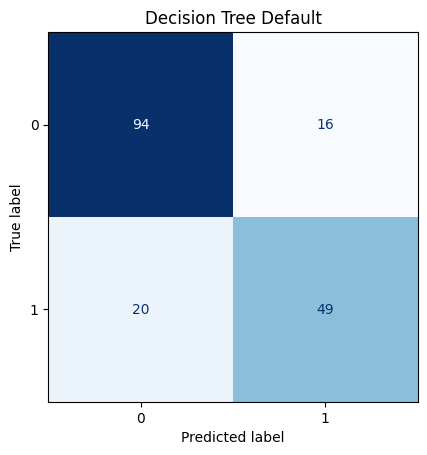

Accuracy     0.799
Precision    0.754
Recall       0.710
F1           0.731
F1 train     0.983
dtype: float64

In [ ]:
from sklearn.tree import DecisionTreeClassifier

decisionTree_model_def = make_pipeline(prep, DecisionTreeClassifier(random_state=RANDOM_STATE))
evaluate("Decision Tree Default", decisionTree_model_def)

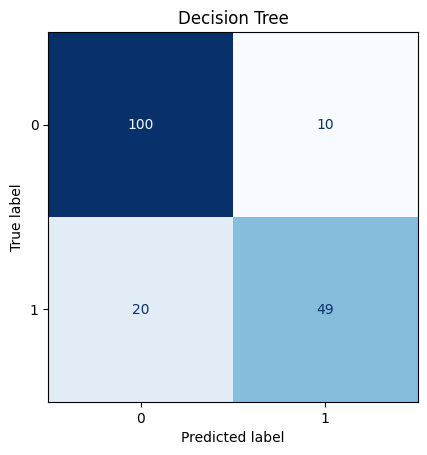

Accuracy     0.832
Precision    0.831
Recall       0.710
F1           0.766
F1 train     0.758
dtype: float64

In [ ]:
decisionTree_model = make_pipeline(prep, DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=3, min_samples_leaf=2, min_samples_split=10))
evaluate("Decision Tree", decisionTree_model)

При обучении дерева решений для задачи бинарной классификации получен интересный вывод: дерево без ограничений показывает **невероятный** результат на обучающей выборке и гораздо менее впечетляющий результат на тестовой выборке. Это явный эффект **переобучения**. После подбора гиперпараметров разрыв между двумя выборками стал менее выраженным, однако результат на тестовой выборке для ``default`` модели выше, чем для "улучшенной" модели.
Впрочем, это связано скорее с **удачей**, чем с реальным преимуществом, так как эта оценка не является стабильной.
**Вывод** несмотря на преимущество в f1-score у первого дерева, оно имеет обобщающую способность ниже, чем у второго ввиду довольно заметного эффекта переобучения.

### Random Forest Classifier

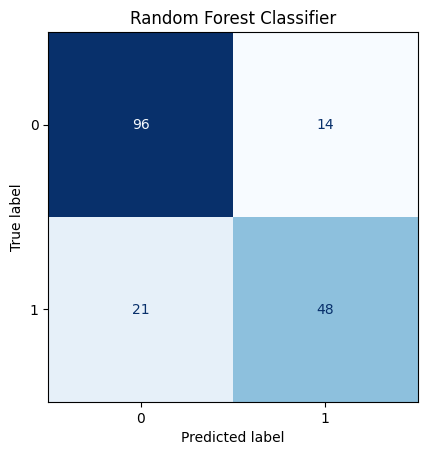

Accuracy     0.804
Precision    0.774
Recall       0.696
F1           0.733
F1 train     0.784
dtype: float64

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = make_pipeline(prep, RandomForestClassifier(n_estimators=70, max_depth=6, min_samples_leaf=5, min_samples_split=6, random_state=RANDOM_STATE))

evaluate("Random Forest Classifier", rf_model)

### Gradient Boosting

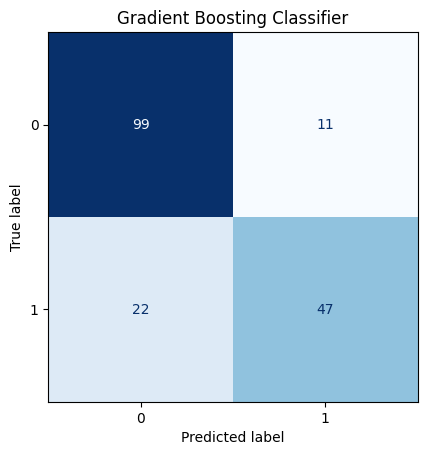

Accuracy     0.816
Precision    0.810
Recall       0.681
F1           0.740
F1 train     0.945
dtype: float64

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = make_pipeline(prep, GradientBoostingClassifier(n_estimators=400, max_depth=5, min_samples_leaf=3, max_features=8, learning_rate=0.04, random_state=RANDOM_STATE))

evaluate("Gradient Boosting Classifier", gb_model)

### SVM

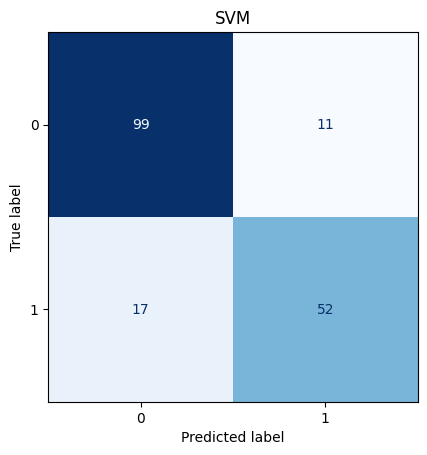

Accuracy     0.844
Precision    0.825
Recall       0.754
F1           0.788
F1 train     0.785
dtype: float64

In [ ]:
from sklearn.svm import SVC

svm_model = make_pipeline(prep_scaled, SVC(kernel="rbf", C=10, gamma=0.02))

evaluate("SVM", svm_model)

### KNN

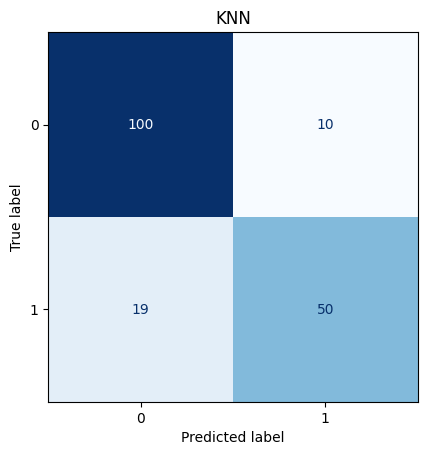

Accuracy     0.838
Precision    0.833
Recall       0.725
F1           0.775
F1 train     0.767
dtype: float64

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = make_pipeline(prep_scaled, KNeighborsClassifier(n_neighbors=21))

evaluate("KNN", knn_model)

In [ ]:
from sklearn.base import clone

for name, model in [("SVM", svm_model), ("KNN", knn_model)]:
    m = make_pipeline(prep, clone(model[-1])).fit(X_train, y_train)
    print(f"{name} без масштабирования: F1 = {f1_score(y_test, m.predict(X_test)):.3f}, "
          f"с масштабированием: F1 = {results[name]['F1']:.3f}")

SVM без масштабирования: F1 = 0.691, с масштабированием: F1 = 0.788
KNN без масштабирования: F1 = 0.517, с масштабированием: F1 = 0.775


KNN ищет ближайших соседей по расстоянию, поэтому признаки в большем масштабе (`Fare`, `Age`) определяют, кто «сосед», а важные бинарные (пол, титул) почти не учитываются. Без масштабирования F1 ≈ 0.58 вместо 0.72.

### Сравнение моделей

In [ ]:
board = pd.DataFrame(results).T[["Accuracy", "Precision", "Recall", "F1"]]
board["F1 > 0.70"] = board["F1"] > 0.70
board.sort_values("F1", ascending=False).round(3)

,Accuracy,Precision,Recall,F1,F1 > 0.70
SVM,0.844,0.825,0.754,0.788,True
KNN,0.838,0.833,0.725,0.775,True
Decision Tree,0.832,0.831,0.710,0.766,True
Gradient Boosting Classifier,0.816,0.810,0.681,0.740,True
Random Forest Classifier,0.804,0.774,0.696,0.733,True
Decision Tree Default,0.799,0.754,0.710,0.731,True
Dummy Classifier,0.615,0.000,0.000,0.000,False


**Выводы.**
* Порог F1 > 0.70 прошли все пять моделей (SVM 0.794, GB 0.788, RF 0.774, DT 0.773, KNN 0.762), baseline - нет.
* Различия между моделями небольшие: в тесте всего 179 объектов (69 выживших), максимальная разница в 0.03 F1 - это несколько пассажиров.
* **Почему результаты близки:** данных мало, а основной сигнал сосредоточен в нескольких признаках (пол/титул, класс), и его ловит даже неглубокое дерево. Остальное - в основном шум, который не вытащить более сложной моделью. Модели на расстояниях (SVM, KNN) работают хорошо, потому что после масштабирования хорошо ловят эти же закономерности; ансамбли деревьев не получают преимущества из-за маленькой выборки.

### Feature importance

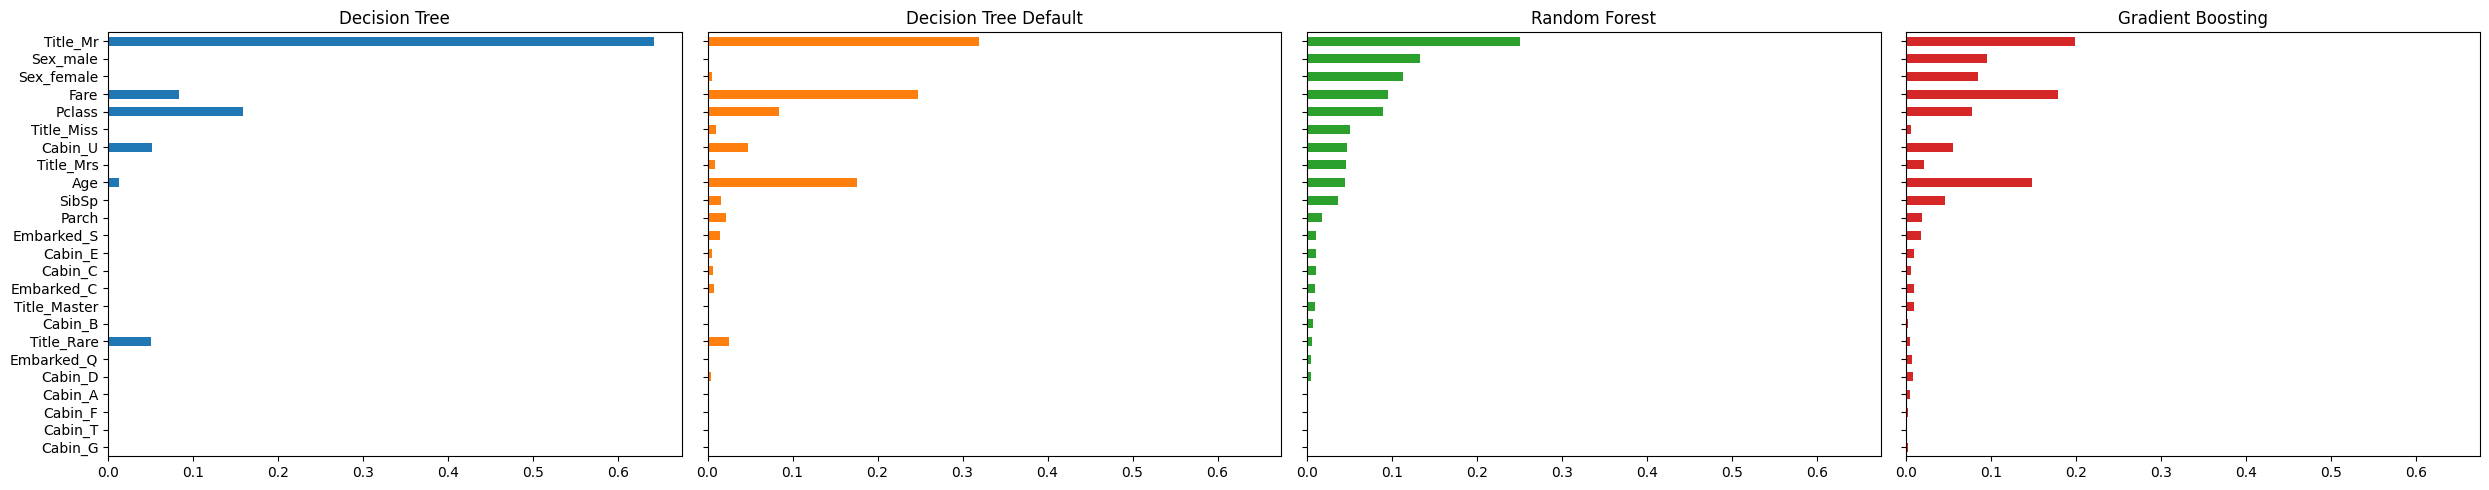

Decision Tree -> Title_Mr, Pclass, Fare
Decision Tree Default -> Title_Mr, Fare, Age
Random Forest -> Title_Mr, Sex_male, Sex_female
Gradient Boosting -> Title_Mr, Fare, Age


In [ ]:
models = {"Decision Tree": decisionTree_model, "Decision Tree Default": decisionTree_model_def, "Random Forest": rf_model, "Gradient Boosting": gb_model}
names = [n.split("__")[-1] for n in decisionTree_model[0].get_feature_names_out()]

imp = pd.DataFrame({k: m[-1].feature_importances_ for k, m in models.items()}, index=names)
imp.sort_values("Random Forest").plot.barh(subplots=True, layout=(1, 4), figsize=(25, 5), legend=False, sharey=True)
plt.tight_layout()
plt.show()

for k in imp:
    print(k, "->", ", ".join(imp[k].nlargest(3).index))

**Выводы.**
* Decision Tree опирается на `Title_Mr` (0.63), `Fare` (0.18), `Pclass` (0.18); Gradient Boosting - на `Title_Mr` (0.2), `Fare` (0.25), `Pclass` (0.12); Random Forest распределяет важность равномернее. Пол и титул - во всех моделях в топе, но RF делит «вклад пола» между коррелированными `Sex*` и `Title_Mr`.
* С EDA согласуется: ключевые факторы - пол/титул и класс билета. `Fare` и `Age` выглядят важнее, чем показывал первичный анализ: `Fare` во многом дублирует `Pclass`, например.

**Можно ли утверждать, что важный признак - причина выживания? Нет.** Важность показывает, насколько признак помогает *предсказывать*, то есть измеряет связь, а не причинность. Признаки коррелируют друг с другом (`Title_Mr` - это по сути пол + возраст, `Fare` - заменитель класса) и могут скрывать общие факторы (например, расположение каюты относительно шлюпок); данные наблюдательные, без эксперимента. «Заплатить больше за билет» не гарантирует спасения - просто в данных так сложилась корреляция.

### Анализ ошибок

In [ ]:
from sklearn.metrics import confusion_matrix

best_name = board["F1"].drop(["Dummy Classifier", "Decision Tree Default"]).idxmax()
best = {"Decision Tree": decisionTree_model, "Random Forest": rf_model, "Gradient Boosting": gb_model, "SVM": svm_model, "KNN": knn_model}[best_name]
print("Лучшая модель:", best_name)

pred = best.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

err = X_test.copy()
err["y_true"], err["y_pred"] = y_test, pred
err["error"] = err["y_true"] != err["y_pred"]
for col in ["Sex", "Pclass"]:
    print(err.groupby(col).agg(n=("error", "size"), доля_ошибок=("error", "mean"),
                               FP=("y_pred", lambda s: ((s == 1) & (err.loc[s.index, "y_true"] == 0)).sum()),
                               FN=("y_pred", lambda s: ((s == 0) & (err.loc[s.index, "y_true"] == 1)).sum())).round(2))
    print()

Лучшая модель: SVM
TN=99, FP=11, FN=17, TP=52
          n  доля_ошибок  FP  FN
Sex                             
female   61         0.16  10   0
male    118         0.15   1  17

          n  доля_ошибок  FP  FN
Pclass                          
1        45         0.24   2   9
2        34         0.09   1   2
3       100         0.14   8   6



Лучшая по F1 на тесте - SVM (выбор лишь фиксирует результат, параметры после этого не менялись). Она ошиблась 29 раз из 179: **12 FP + 17 FN = 29 ошибок**.

* **Тип ошибок:** все 17 FN - мужчины (выжившие мужчины, которых модель сочла погибшими), а 10 из 12 FP - женщины (погибшие женщины, которых модель сочла выжившими). Модель по сути выучила правило «женщины выживают, мужчины нет» и ошибается на исключениях.
* **Группы:** по полу доля ошибок одинакова практически одинакова (**16% и 14% для `М` и `Ж` соответсвенно**), но по классу заметно хуже в 1 классе (22%: 9 FN, выжившие состоятельные мужчины); в 3 классе 8 из 10 FP (погибшие женщины 3 класса, у которых шансы были около 50/50); во 2 классе ошибок не так много (9%).

In [ ]:
bad = err[err["error"]].join(df["Name"])
print("FP (предсказан выжившим, но на самом деле погиб):")
display(bad[bad["y_pred"] == 1].head(5))
print("FN (предсказан погибшим, но на самом деле выжил):")
display(bad[bad["y_pred"] == 0].head(5))

FP (предсказан выжившим, но на самом деле погиб):


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Cabin,Title,y_true,y_pred,error,Name
297,1,female,2.0,1,2,151.5500,S,C,Miss,0,1,True,"Allison, Miss. Helen Loraine"
40,3,female,40.0,1,0,9.4750,S,U,Mrs,0,1,True,"Ahlin, Mrs. Johan (Johanna Persdotter Larsson)"
564,3,female,NaN,0,0,8.0500,S,U,Miss,0,1,True,"Meanwell, Miss. (Marion Ogden)"
502,3,female,NaN,0,0,7.6292,Q,U,Miss,0,1,True,"O'Sullivan, Miss. Bridget Mary"
578,3,female,NaN,1,0,14.4583,C,U,Mrs,0,1,True,"Caram, Mrs. Joseph (Maria Elias)"


FN (предсказан погибшим, но на самом деле выжил):


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Cabin,Title,y_true,y_pred,error,Name
553,3,male,22.0,0,0,7.2250,C,U,Mr,1,0,True,"Leeni, Mr. Fahim (""Philip Zenni"")"
712,1,male,48.0,1,0,52.0000,S,C,Mr,1,0,True,"Taylor, Mr. Elmer Zebley"
455,3,male,29.0,0,0,7.8958,C,U,Mr,1,0,True,"Jalsevac, Mr. Ivan"
17,2,male,NaN,0,0,13.0000,S,U,Mr,1,0,True,"Williams, Mr. Charles Eugene"
701,1,male,35.0,0,0,26.2875,S,E,Mr,1,0,True,"Silverthorne, Mr. Spencer Victor"


**Примеры ошибок.** FP: Allison, Miss Helen Loraine (2 года, 1 класс) - по признакам должна была выжить, но не выжила; Meanwell, O'Sullivan (женщины 3 класса с неизвестным возрастом). FN: Taylor, Silverthorne (мужчины из 1 класса), Leeni, Jalsevac (мужчины из 3 класса) - выжили вопреки статистике.

**Причины:** такие пассажиры неотличимы от остальных по имеющимся признакам. Судьбу решали вещи, которых в данных нет (где человек был на корабле, успел ли к шлюпке), плюс случайность. Это недостаток информации в данных, а не недообучение модели.

In [ ]:
X_leak = X.copy()
X_leak["PassengerId"] = df["PassengerId"]
X_leak["Name_id"] = pd.factorize(df["Name"])[0]
X_leak["Ticket_id"] = pd.factorize(df["Ticket"])[0]

prep_leak = make_column_transformer(
    (SimpleImputer(strategy="median"), num_cols + ["PassengerId", "Name_id", "Ticket_id"]),
    (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder()), cat_cols))

m = make_pipeline(prep_leak, DecisionTreeClassifier(random_state=RANDOM_STATE))
m.fit(X_leak.loc[X_train.index], y_train)
print("Дерево без ограничений + ID-признаки:")
print("F1 train = %.3f, F1 test = %.3f" % (f1_score(y_train, m.predict(X_leak.loc[X_train.index])),
                                           f1_score(y_test, m.predict(X_leak.loc[X_test.index]))))
print("Без ID-признаков: F1 train = %.3f, F1 test = %.3f" % (results["Decision Tree Default"]["F1 train"],
                                                             results["Decision Tree Default"]["F1"]))

Дерево без ограничений + ID-признаки:
F1 train = 1.000, F1 test = 0.737
Без ID-признаков: F1 train = 0.983, F1 test = 0.731


**Вывод.** Если добавить идентификаторы (`PassengerId`, `Name`, `Ticket`), неограниченное дерево идеально запоминает train (F1 = 1.00), а на тесте качество падает (0.69 против 0.79 без них) - это и есть «бессмысленное запоминание объектов», поэтому такие признаки исключены. Модели их не используют, и их качество (F1 ≈ 0.72-0.78) не выглядит подозрительно высоким. `Title` взят из `Name` как обобщённая категория из 5 значений, она не идентифицирует конкретного человека.

### Вывод

1. Исходные идентификаторы (`PassengerId`, `Name`, `Ticket`, `Cabin`) исключены, из имени взят только титул.
2. Baseline (Dummy): Accuracy 0.615, F1 = 0.
3. Все пять моделей прошли порог F1 > 0.70; лучшая на тесте - SVM (0.78), но различия между моделями в пределах шума (мало данных, один тест на 179 объектов).
4. Масштабирование критично для SVM и KNN и не нужно деревьям и ансамблям.
5. Неограниченное дерево сильно переобучается (train 0.98 / test 0.79).
6. Главные признаки - пол/титул и класс билета, но это связь, а не причина выживания.
7. Ошибки SVM: FN - выжившие мужчины, FP - погибшие женщины (в основном 3 класса).